In [1]:
import os
import time
import math
import numpy as np
import random
from pathlib import Path
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns

nsol = 50
alpha = 0.1
r = 0.25
nombre_estudiante = "JeronimoGil"  
ruta_instancias = Path("instancias")
archivos = [f for f in os.listdir(ruta_instancias) if f.endswith(".txt")]
archivos.sort(key=lambda x: int(x.split('_')[1].replace('.txt', '')))
instancias = archivos

### Lectura de las instacias

In [2]:
def leer_instancia(nombre_archivo):
    ruta = ruta_instancias / nombre_archivo

    with open(ruta, "r") as archivo:
        lineas = [linea.strip() for linea in archivo if linea.strip()]
    n, m = map(int, lineas[0].split())

    pesos = []
    adyacencia = []

    for i in range(1, n + 1):
        datos = list(map(int, lineas[i].split()))
        peso = datos[0]
        num_vecinos = datos[1]
        vecinos_originales = datos[2:2 + num_vecinos]

        nodo = i - 1
        vecinos = [
            v for v in vecinos_originales
            if v != nodo
        ]
        pesos.append(peso)
        adyacencia.append(vecinos)

    
    for u in range(n):
        for v in adyacencia[u]:
            if v < 0 or v >= n:
                raise ValueError(
                    f"Instancia {nombre_archivo}: "
                    f"vecino {v} fuera de rango para nodo {u}. "
                    f"Se esperaba un índice entre 0 y {n-1}."
                )

    preasignados = {}
    for i in range(n + 1, n + 1 + m):
        nodo, color = map(int, lineas[i].split())
        if nodo < 0 or nodo >= n:
            raise ValueError(
                f"Instancia {nombre_archivo}: "
                f"nodo preasignado {nodo} fuera de rango."
            )
        if color < 0:
            raise ValueError(
                f"Instancia {nombre_archivo}: "
                f"color preasignado {color} inválido."
            )
        preasignados[nodo] = color

    for u in range(n):
        for v in adyacencia[u]:
            if u not in adyacencia[v]:
                raise ValueError(
                    f"Instancia {nombre_archivo}: "
                    f"la arista ({u},{v}) no es simétrica."
                )

    return {
        "nombre": nombre_archivo,
        "n": n,
        "m": m,
        "pesos": pesos,
        "adyacencia": adyacencia,
        "preasignados": preasignados
    }

### Evaluación factibilidad de la solución

In [3]:
def validar_solucion(solucion, instancia):

    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    preasignados = instancia["preasignados"]

    if isinstance(solucion, dict):
        if len(solucion) != n:
            return False, "La solución no tiene n colores."
        try:
            solucion_lista = [
                solucion[i] for i in range(n)
            ]
        except KeyError:
            return False, "Faltan nodos en la solución."
    elif isinstance(solucion, (list, tuple)):
        solucion_lista = list(solucion)
    else:
        return False, "Formato de solución no válido."
    if len(solucion_lista) != n:
        return False, "La solución no tiene n colores."
    if any(
        c is None or c == -1
        for c in solucion_lista
    ):
        return False, "Existen nodos sin color."
    for c in solucion_lista:

        if not isinstance(c, (int, np.integer)):
            return False, "Existen etiquetas que no son enteras."

        if c < 0:
            return False, "Existe una etiqueta negativa."
    for nodo, color_fijo in preasignados.items():
        if solucion_lista[nodo] != color_fijo:
            return False, (
                f"El nodo {nodo} tenía color preasignado "
                f"{color_fijo}, pero recibió "
                f"{solucion_lista[nodo]}."
            )
    for u in range(n):
        for v in adyacencia[u]:
            if solucion_lista[u] == solucion_lista[v]:
                return False, (
                    f"Conflicto de color entre los nodos "
                    f"{u} y {v}."
                )
    colores_usados = sorted(set(solucion_lista))
    colores_esperados = list(range(len(colores_usados)))
    if colores_usados != colores_esperados:
        return False, (
            f"Las etiquetas no son consecutivas. "
            f"Usadas: {colores_usados}. "
            f"Esperadas: {colores_esperados}."
        )
    return True, "Solución factible."

In [4]:
def evaluar_solucion(solucion, instancia):
    es_valida, mensaje = validar_solucion(solucion, instancia)
    
    if not es_valida:
        n = instancia["n"]
        suma_pesos = sum(instancia["pesos"])
        return n, suma_pesos, 999999.0  

    pesos = instancia["pesos"]
    pesos_por_color = {}

    if isinstance(solucion, dict):
        for nodo, color in solucion.items():
            if color not in pesos_por_color:
                pesos_por_color[color] = 0
            pesos_por_color[color] += pesos[nodo]
    else:
        for nodo, color in enumerate(solucion):
            if color not in pesos_por_color:
                pesos_por_color[color] = 0
            pesos_por_color[color] += pesos[nodo]

    z1 = len(pesos_por_color)
    pesos_colores = list(pesos_por_color.values())
    
    if not pesos_colores:
        return instancia["n"], sum(pesos), 999999.0

    z2 = max(pesos_colores) - min(pesos_colores)
    suma_pesos = sum(pesos)
    valor_combinado = 100.0 * (z1 + (z2 / suma_pesos if suma_pesos > 0 else 0))
    return z1, z2, valor_combinado

In [5]:
def evaluar_objetivo(solucion, instancia):
    pesos = instancia["pesos"]
    pesos_por_color = {}
    for nodo, color in enumerate(solucion):
        if color not in pesos_por_color:
            pesos_por_color[color] = 0
        pesos_por_color[color] += pesos[nodo]
    z1 = len(pesos_por_color)
    pesos_colores = list(pesos_por_color.values())
    if not pesos_colores:
        return 999999.0
    z2 = max(pesos_colores) - min(pesos_colores)
    suma_pesos = sum(pesos)
    objetivo = 100.0 * (
        z1 +
        (z2 / suma_pesos if suma_pesos > 0 else 0)
    )
    return objetivo

### Solución inicial

In [6]:
def algoritmo_constructivo(instancia):
    t_inicio = time.time()
    SEED = 29
    random.seed(SEED)
    np.random.seed(SEED)
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    pesos = instancia["pesos"]
    preasignados = instancia["preasignados"]
    
    if n == 0:
        return {}, 0, 0, 0.0, 0.0
    
    colores = {i: -1 for i in range(n)}
    saturacion = [0] * n
    
    for u, color in preasignados.items():
        colores[u] = color
        
    for u in range(n):
        if colores[u] != -1:
            continue
        colores_vecinos = {colores[v] for v in adyacencia[u] if colores[v] != -1}
        saturacion[u] = len(colores_vecinos)
        
    while any(colores[i] == -1 for i in range(n)):
        candidatos = [i for i in range(n) if colores[i] == -1]
        if not candidatos:
            break
            
        max_sat = max(saturacion[i] for i in candidatos)
        candidatos_sat = [i for i in candidatos if saturacion[i] == max_sat]
        nodo_sel = max(candidatos_sat, key=lambda x: (pesos[x], len(adyacencia[x])))
        
        colores_prohibidos = {colores[v] for v in adyacencia[nodo_sel] if colores[v] != -1}
        colores_usados = set(colores[i] for i in range(n) if colores[i] != -1)
        pesos_por_color = {}
        for c in colores_usados:
            pesos_por_color[c] = sum(pesos[i] for i in range(n) if colores[i] == c)
            
        colores_validos = [c for c in colores_usados if c not in colores_prohibidos]
        
        if colores_validos:
            color_elegido = min(colores_validos, key=lambda c: pesos_por_color[c])
        else:
            color_elegido = 0
            while color_elegido in colores_prohibidos or color_elegido in colores_usados:
                color_elegido += 1
                
        colores[nodo_sel] = color_elegido
        for v in adyacencia[nodo_sel]:
            if colores[v] == -1:
                colores_vecinos_v = {colores[w] for w in adyacencia[v] if colores[w] != -1}
                saturacion[v] = len(colores_vecinos_v)
                
    t_fin = time.time()
    t_ejecucion = round(t_fin - t_inicio, 4)
    t_fin = time.time()
    t_ejecucion = round(t_fin - t_inicio, 4)
    
    z1, z2, f_obj = evaluar_solucion(colores, instancia)
    
    return colores, z1, z2, round(f_obj, 2), t_ejecucion

def algoritmo_grasp(instancia, p_alpha=alpha, p_nsol=nsol):
    inicio = time.perf_counter()
    SEED = 29
    random.seed(SEED)
    np.random.seed(SEED)
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    pesos = instancia["pesos"]
    preasignados = instancia["preasignados"]
    mejor_solucion = None
    mejor_z1 = float("inf")
    mejor_z2 = float("inf")
    mejor_obj = float("inf")
    for _ in range(p_nsol):
        solucion = [-1] * n
        for nodo, color in preasignados.items():
            solucion[nodo] = color
        colores_vecinos = [set() for _ in range(n)]
        for u in range(n):
            if solucion[u] != -1:
                for v in adyacencia[u]:
                    colores_vecinos[v].add(solucion[u])

      
        while -1 in solucion:
            candidatos = []
            for u in range(n):
                if solucion[u] != -1:
                    continue
                saturacion = len(colores_vecinos[u])
                grado = len(adyacencia[u])
                candidatos.append(
                    (u, saturacion, grado)
                )

            max_sat = max(x[1] for x in candidatos)
            max_grado = max(x[2] for x in candidatos)
            puntuaciones = []
            for u, sat, grado in candidatos:
                sat_norm = (
                    sat / max_sat
                    if max_sat > 0
                    else 0
                )
                grado_norm = (
                    grado / max_grado
                    if max_grado > 0
                    else 0
                )
                score = sat_norm + grado_norm

                puntuaciones.append((u, score))

            max_score = max(score for _, score in puntuaciones)
            min_score = min(score for _, score in puntuaciones)
            umbral = (max_score - p_alpha * (max_score - min_score))
            rcl = [
                u
                for u, score in puntuaciones
                if score >= umbral
            ]

            u = random.choice(rcl)
            prohibidos = colores_vecinos[u]
            color = 0
            while color in prohibidos:
                color += 1
            solucion[u] = color

            for v in adyacencia[u]:
                if solucion[v] == -1:
                    colores_vecinos[v].add(color)
        z1, z2, obj = evaluar_solucion(
            solucion,
            instancia
        )

        if (z1 < mejor_z1 or (z1 == mejor_z1 and z2 < mejor_z2)):
            mejor_solucion = solucion.copy()
            mejor_z1 = z1
            mejor_z2 = z2
            mejor_obj = obj

    tiempo = time.perf_counter() - inicio
    return (
        mejor_solucion,
        mejor_z1,
        mejor_z2,
        mejor_obj,
        tiempo
    )
    
def algoritmo_ruido(instancia, p_r=r, p_nsol=nsol):
    SEED = 29
    random.seed(SEED)
    np.random.seed(SEED)
    inicio = time.perf_counter()
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    pesos = instancia["pesos"]
    preasignados = instancia["preasignados"]

    mejor_solucion = None
    mejor_z1 = float("inf")
    mejor_z2 = float("inf")
    mejor_obj = float("inf")
    for _ in range(p_nsol):

        pesos_ruidosos = [
            peso * (
                1 + random.uniform(-p_r, p_r)
            )
            for peso in pesos
        ]

        max_peso = max(pesos_ruidosos)
        solucion = [-1] * n

        for nodo, color in preasignados.items():
            solucion[nodo] = color
        colores_vecinos = [set() for _ in range(n)]
        for u in range(n):
            if solucion[u] != -1:
                for v in adyacencia[u]:
                    colores_vecinos[v].add(solucion[u])

        while -1 in solucion:
            candidatos = []
            for u in range(n):
                if solucion[u] != -1:
                    continue
                saturacion = len(colores_vecinos[u])

                peso_norm = (
                    pesos_ruidosos[u] / max_peso
                    if max_peso > 0
                    else 0
                )
                score = (2.0 * saturacion + peso_norm)
                candidatos.append((u, score))

            u = max(candidatos,key=lambda x: x[1])[0]
            prohibidos = colores_vecinos[u]
            color = 0
            while color in prohibidos:
                color += 1
            solucion[u] = color

            for v in adyacencia[u]:

                if solucion[v] == -1:
                    colores_vecinos[v].add(color)

        
        z1, z2, obj = evaluar_solucion(
            solucion,
            instancia
        )

        if (
            z1 < mejor_z1
            or
            (z1 == mejor_z1 and z2 < mejor_z2)
        ):

            mejor_solucion = solucion.copy()
            mejor_z1 = z1
            mejor_z2 = z2
            mejor_obj = obj

    tiempo = time.perf_counter() - inicio
    return (
        mejor_solucion,
        mejor_z1,
        mejor_z2,
        mejor_obj,
        tiempo
    )

### Guardar resultados

In [7]:
def guardar_resultados_excel(resultados, metodo):
    wb = openpyxl.Workbook()
    wb.remove(wb.active)
    for nom_instancia, datos in resultados.items():
        sol, z1, z2, obj, t_comp = datos
        
        nombre_limpio = str(nom_instancia).replace(".txt", "")
        
        ws = wb.create_sheet(title=nombre_limpio[:31])
        if isinstance(sol, dict):
            lista_colores = [sol[i] for i in sorted(sol.keys())]
        elif isinstance(sol, (list, tuple)):
            lista_colores = list(sol)
        else:
            lista_colores = [0]
            
        ws.append(lista_colores)
        ws.append([int(z1), int(z2), round(float(obj), 2), round(float(t_comp), 2)])
        
    nombre_archivo = f"GCP_JeronimoGil_{metodo}.xlsx"
    wb.save(nombre_archivo)
    print(f"Archivo Excel generado con éxito: {nombre_archivo}")

### Vecindarios

In [8]:
def obtener_metricas_colores(solucion_actual, pesos):
    pesos_color = {}
    frecuencia = {}
    for i, c in enumerate(solucion_actual):
        pesos_color[c] = pesos_color.get(c, 0) + pesos[i]
        frecuencia[c] = frecuencia.get(c, 0) + 1
        
    c_pesado = max(pesos_color, key=pesos_color.get)
    c_liviano = min(pesos_color, key=pesos_color.get)
    return c_pesado, c_liviano, pesos_color, frecuencia

def reparar_etiquetas(solucion, instancia):
    solucion_reparada = list(solucion)
    preasignados = instancia["preasignados"]
    colores_actuales = sorted(set(solucion_reparada))
    n_colores = len(colores_actuales)
    colores_fijos = set(preasignados.values())

    if any(
        color < 0 or color >= n_colores
        for color in colores_fijos
    ):
        return solucion_reparada

    etiquetas_disponibles = [
        color
        for color in range(n_colores)
        if color not in colores_fijos
    ]
    colores_movibles = [
        color
        for color in colores_actuales
        if color not in colores_fijos
    ]

    mapa_colores = {}

    for color in colores_fijos:
        mapa_colores[color] = color

    for color_viejo, color_nuevo in zip(
        colores_movibles,
        etiquetas_disponibles
    ):
        mapa_colores[color_viejo] = color_nuevo

    for nodo in range(len(solucion_reparada)):
        color_actual = solucion_reparada[nodo]
        solucion_reparada[nodo] = (
            mapa_colores[color_actual]
        )
    return solucion_reparada
    
def construir_estructuras_coloreo(solucion, instancia):
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]

    colores_nodos = {}
    for v in range(n):
        c = solucion[v]
        if c not in colores_nodos:
            colores_nodos[c] = []
        colores_nodos[c].append(v)
    conteo_vecinos_color = [dict() for _ in range(n)]

    for v in range(n):
        conteos = conteo_vecinos_color[v]
        for u in adyacencia[v]:
            c = solucion[u]
            conteos[c] = conteos.get(c, 0) + 1
    colores_vecinos = [
        set(conteo_vecinos_color[v].keys())
        for v in range(n)
    ]
    grados = [
        len(adyacencia[v])
        for v in range(n)
    ]
    return (
        colores_nodos,
        conteo_vecinos_color,
        colores_vecinos,
        grados
    )

def es_movimiento_1move_valido(nodo,nuevo_color,solucion,conteo_vecinos_color):
    return conteo_vecinos_color[nodo].get(nuevo_color, 0) == 0

def es_movimiento_swap_valido(i,j,solucion,conteo_vecinos_color,adyacencia):
    color_i = solucion[i]
    color_j = solucion[j]
    if color_i == color_j:
        return False

    conflictos_i = conteo_vecinos_color[i].get(color_j, 0)
    conflictos_j = conteo_vecinos_color[j].get(color_i, 0)
    if j in adyacencia[i]:
        conflictos_i -= 1
    if i in adyacencia[j]:
        conflictos_j -= 1
    return conflictos_i == 0 and conflictos_j == 0

#### Vecindario 1 - 1-Move

In [9]:
def get_N1_neighbors(solucion_actual, instancia):
    n = instancia["n"]
    pesos = instancia["pesos"]
    preasignados = set(instancia["preasignados"].keys())
    c_pesado, c_liviano, _, frecuencia = \
        obtener_metricas_colores(
            solucion_actual,
            pesos
        )
    colores_unicos = list(frecuencia.keys())
    (
        colores_nodos,
        conteo_vecinos_color,
        colores_vecinos,
        grados
    ) = construir_estructuras_coloreo(
        solucion_actual,
        instancia
    )
    candidatos = [
        v for v in range(n)
        if v not in preasignados
    ]
    candidatos.sort(
        key=lambda v: (
            solucion_actual[v] == c_pesado,
            grados[v]
        ),
        reverse=True
    )

    for nodo in candidatos:
        color_actual = solucion_actual[nodo]
        colores_candidatos = []
        if c_liviano != color_actual:
            colores_candidatos.append(c_liviano)
        for c in colores_unicos:
            if c != color_actual and c != c_liviano:
                colores_candidatos.append(c)
        for nuevo_color in colores_candidatos:
            if conteo_vecinos_color[nodo].get(
                nuevo_color, 0
            ) != 0:
                continue
            vecino_sol = list(solucion_actual)
            vecino_sol[nodo] = nuevo_color
            yield vecino_sol

#### Vecindario 2 - Swap

In [10]:
def get_N2_neighbors(solucion_actual, instancia):
    n = instancia["n"]
    pesos = instancia["pesos"]
    adyacencia = instancia["adyacencia"]
    preasignados = set(instancia["preasignados"].keys())

    c_pesado, c_liviano, _, _ = \
        obtener_metricas_colores(
            solucion_actual,
            pesos
        )
    colores_importantes = {
        c_pesado,
        c_liviano
    }

    (
        colores_nodos,
        conteo_vecinos_color,
        colores_vecinos,
        grados
    ) = construir_estructuras_coloreo(
        solucion_actual,
        instancia
    )

    candidatos = [
        v for v in range(n)
        if v not in preasignados
    ]
    candidatos.sort(
        key=lambda v: (
            solucion_actual[v] in colores_importantes,
            grados[v]
        ),
        reverse=True
    )

    for pos_i in range(len(candidatos)):

        i = candidatos[pos_i]
        color_i = solucion_actual[i]

        for pos_j in range(pos_i + 1, len(candidatos)):

            j = candidatos[pos_j]
            color_j = solucion_actual[j]

            if color_i == color_j:
                continue

            if (
                color_i not in colores_importantes
                and color_j not in colores_importantes
            ):
                continue

            if not es_movimiento_swap_valido(
                i,
                j,
                solucion_actual,
                conteo_vecinos_color,
                adyacencia
            ):
                continue

            vecino_sol = list(solucion_actual)
            vecino_sol[i] = color_j
            vecino_sol[j] = color_i
            yield vecino_sol

#### Vecindario 3 - Recolaración

In [11]:
def get_N3_neighbors(solucion_actual, instancia):
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    preasignados = set(instancia["preasignados"].keys())
    MAX_PARES_POR_COLOR = 5
    MAX_COLORES_DESTINO = 3

    colores = sorted(set(solucion_actual))
    if not colores:
        return

    nodos_por_color = {}
    for nodo in range(n):
        if nodo in preasignados:
            continue
        color = solucion_actual[nodo]
        if color not in nodos_por_color:
            nodos_por_color[color] = []
        nodos_por_color[color].append(nodo)
    for color_origen in sorted(nodos_por_color.keys()):
        nodos = nodos_por_color[color_origen]
        if len(nodos) < 2:
            continue
        pares = []
        for i in range(len(nodos)):
            for j in range(i + 1, len(nodos)):
                pares.append(
                    (nodos[i], nodos[j])
                )
                if len(pares) >= MAX_PARES_POR_COLOR:
                    break
            if len(pares) >= MAX_PARES_POR_COLOR:
                break

        for v1, v2 in pares:
            colores_factibles_v1 = []
            for color_destino in colores:
                if color_destino == color_origen:
                    continue
                conflicto = False
                for vecino in adyacencia[v1]:
                    if vecino == v2:
                        continue
                    if solucion_actual[vecino] == color_destino:
                        conflicto = True
                        break
                if not conflicto:
                    colores_factibles_v1.append(
                        color_destino
                    )
            colores_factibles_v2 = []
            for color_destino in colores:
                if color_destino == color_origen:
                    continue
                conflicto = False
                for vecino in adyacencia[v2]:
                    if vecino == v1:
                        continue
                    if solucion_actual[vecino] == color_destino:
                        conflicto = True
                        break
                if not conflicto:
                    colores_factibles_v2.append(
                        color_destino
                    )
            colores_factibles_v1 = (
                colores_factibles_v1[
                    :MAX_COLORES_DESTINO
                ]
            )
            colores_factibles_v2 = (
                colores_factibles_v2[
                    :MAX_COLORES_DESTINO
                ]
            )
            if (
                not colores_factibles_v1
                or not colores_factibles_v2
            ):
                continue
            for color_v1 in colores_factibles_v1:
                for color_v2 in colores_factibles_v2:
                    if (
                        v2 in adyacencia[v1]
                        and color_v1 == color_v2
                    ):
                        continue

                    vecino_sol = list(solucion_actual)
                    vecino_sol[v1] = color_v1
                    vecino_sol[v2] = color_v2

                    factible = True
                    for nodo in (v1, v2):
                        color_nuevo = vecino_sol[nodo]
                        for vecino in adyacencia[nodo]:
                            if vecino == v1 or vecino == v2:
                                continue
                            if vecino_sol[vecino] == color_nuevo:
                                factible = False
                                break
                        if not factible:
                            break
                    if not factible:
                        continue

                    vecino_sol = reparar_etiquetas(
                        vecino_sol,
                        instancia
                    )
                    yield vecino_sol

### Estrategias de busqueda FI y BI

In [12]:
def first_improvement(sol_inicial, instancia, funcion_vecindario):
    mejor_solucion = list(sol_inicial)
    mejor_f = evaluar_objetivo(
        mejor_solucion,
        instancia
    )
    mejora = True
    while mejora:
        mejora = False
        for sol_vecina in funcion_vecindario(
            mejor_solucion,
            instancia
        ):
            f_vecina = evaluar_objetivo(
                sol_vecina,
                instancia
            )
            if f_vecina < mejor_f:
                mejor_solucion = sol_vecina
                mejor_f = f_vecina
                mejora = True
                break
    return mejor_solucion, mejor_f

def best_improvement(sol_inicial, instancia, funcion_vecindario):
    mejor_solucion = list(sol_inicial)
    mejor_f = evaluar_objetivo(
        mejor_solucion,
        instancia
    )
    mejora = True
    while mejora:
        mejora = False
        mejor_vecino_local = None
        mejor_f_local = mejor_f
        for sol_vecina in funcion_vecindario(
            mejor_solucion,
            instancia
        ):
            f_vecina = evaluar_objetivo(
                sol_vecina,
                instancia
            )
            if f_vecina < mejor_f_local:
                mejor_vecino_local = sol_vecina
                mejor_f_local = f_vecina
        if mejor_vecino_local is not None:
            mejor_solucion = mejor_vecino_local
            mejor_f = mejor_f_local
            mejora = True
    return mejor_solucion, mejor_f

### Ejecución 

In [13]:
archivos_instancias = [f"GCP_{i}.txt" for i in range(1, 20)]

configuraciones = [
    ("FI_N1", first_improvement, get_N1_neighbors),
    ("FI_N2", first_improvement, get_N2_neighbors),
    ("FI_N3", first_improvement, get_N3_neighbors),
    ("BI_N1", best_improvement, get_N1_neighbors),
    ("BI_N2", best_improvement, get_N2_neighbors),
    ("BI_N3", best_improvement, get_N3_neighbors)
]

soluciones_iniciales = {}
instancias = {}

SEED = 123
random.seed(SEED)

print("Generando soluciones iniciales\n")

for archivo in archivos_instancias:
    try:
        instancia = leer_instancia(archivo)
        instancias[archivo] = instancia
        sol_dict, z1_ini, z2_ini, f_ini, tiempo_ruido = algoritmo_ruido(
            instancia
        )
        sol_inicial_lista = [
            sol_dict[i]
            for i in range(instancia["n"])
        ]
        soluciones_iniciales[archivo] = sol_inicial_lista
        print(
            f"{archivo} -> "
            f"FO Inicial: {f_ini:.2f}"
        )
    except FileNotFoundError:
        print(f"No se encontró {archivo}")
    except Exception as e:
        print(f"Error procesando {archivo}: {e}")

print("\nIniciando ejecución de las 6 combinaciones")

for metodo_actual, estrategia_func, vecindario_func in configuraciones:

    print(f"Ejecutando Método: {metodo_actual}")
    resultados_corrida = {}
    for archivo in archivos_instancias:
        if archivo not in soluciones_iniciales:
            continue

        try:
            instancia = instancias[archivo]
            sol_inicial_lista = soluciones_iniciales[archivo].copy()
            z1_ini, z2_ini, f_obj_ini = evaluar_solucion(
                sol_inicial_lista,
                instancia
            )

            t0 = time.time()
            sol_final, f_final = estrategia_func(
                sol_inicial_lista,
                instancia,
                vecindario_func
            )
            t_exe_bl = time.time() - t0
            z1_fin, z2_fin, f_obj_fin = evaluar_solucion(
                sol_final,
                instancia
            )
            
            mejora = f_obj_ini - f_obj_fin
            if f_obj_ini != 0:
                mejora_porcentaje = (
                    100 * mejora / f_obj_ini
                )
            else:
                mejora_porcentaje = 0
            resultados_corrida[archivo] = (
                sol_final,
                z1_fin,
                z2_fin,
                f_obj_fin,
                t_exe_bl
            )
            print(
                f"{archivo} | "
                f"Inicial: {f_obj_ini:.2f} | "
                f"Final: {f_obj_fin:.2f} | "
                f"Mejora: {mejora:.2f} "
                f"({mejora_porcentaje:.2f}%)"
            )
        except Exception as e:
            print(
                f"Error procesando {archivo}: {e}"
            )

    if resultados_corrida:
        guardar_resultados_excel(
            resultados_corrida,
            metodo_actual
        )


print(
    "\nEjecución total finalizada. "
    "Todos los archivos Excel están listos."
)

Generando soluciones iniciales

GCP_1.txt -> FO Inicial: 430.64
GCP_2.txt -> FO Inicial: 426.03
GCP_3.txt -> FO Inicial: 900.00
GCP_4.txt -> FO Inicial: 7303.39
GCP_5.txt -> FO Inicial: 7303.32
GCP_6.txt -> FO Inicial: 1906.09
GCP_7.txt -> FO Inicial: 819.78
GCP_8.txt -> FO Inicial: 822.46
GCP_9.txt -> FO Inicial: 4928.71
GCP_10.txt -> FO Inicial: 4925.92
GCP_11.txt -> FO Inicial: 4941.64
GCP_12.txt -> FO Inicial: 4936.17
GCP_13.txt -> FO Inicial: 2005.54
GCP_14.txt -> FO Inicial: 1404.17
GCP_15.txt -> FO Inicial: 2804.83
GCP_16.txt -> FO Inicial: 2904.13
GCP_17.txt -> FO Inicial: 1349.91
GCP_18.txt -> FO Inicial: 1347.77
GCP_19.txt -> FO Inicial: 12701.47

Iniciando ejecución de las 6 combinaciones
Ejecutando Método: FI_N1
GCP_1.txt | Inicial: 430.64 | Final: 406.10 | Mejora: 24.55 (5.70%)
GCP_2.txt | Inicial: 426.03 | Final: 406.10 | Mejora: 19.93 (4.68%)
GCP_3.txt | Inicial: 900.00 | Final: 900.00 | Mejora: 0.00 (0.00%)
GCP_4.txt | Inicial: 7303.39 | Final: 7301.98 | Mejora: 1.41 (0

### Verificación de las soluciones

In [14]:
nombre_base = "GCP_JeronimoGil"
carpeta_entrega1 = Path("soluciones_entrega1")
archivos = {
    "Constructivo": carpeta_entrega1 / f"{nombre_base}_constructivo.xlsx",
    "GRASP": carpeta_entrega1 / f"{nombre_base}_GRASP.xlsx",
    "Ruido": carpeta_entrega1 / f"{nombre_base}_Ruido.xlsx",
    "FI_N1": Path(f"{nombre_base}_FI_N1.xlsx"),
    "FI_N2": Path(f"{nombre_base}_FI_N2.xlsx"),
    "FI_N3": Path(f"{nombre_base}_FI_N3.xlsx"),
    "BI_N1": Path(f"{nombre_base}_BI_N1.xlsx"),
    "BI_N2": Path(f"{nombre_base}_BI_N2.xlsx"),
    "BI_N3": Path(f"{nombre_base}_BI_N3.xlsx")
}

resumen_validacion = {}
print("REVISIÓN DE FACTIBILIDAD")

for metodo, ruta in archivos.items():

    print(f"\n{metodo}")
    if not ruta.exists():

        print(f"No se encontró: {ruta}")
        resumen_validacion[metodo] = {
            "válidas": 0,
            "inválidas": 0,
            "total": 0,
            "estado": "ARCHIVO NO ENCONTRADO"
        }
        continue
    wb = openpyxl.load_workbook(
        ruta,
        data_only=True
    )

    validas = 0
    invalidas = 0
    errores = []
    for ws in wb.worksheets:
        nombre_instancia = ws.title
        fila_solucion = list(
            ws.iter_rows(
                min_row=1,
                max_row=1,
                values_only=True
            )
        )[0]

        solucion = list(fila_solucion)

        nombre_archivo_instancia = (
            f"{nombre_instancia}.txt"
        )
        try:
            instancia = leer_instancia(
                nombre_archivo_instancia
            )
        except Exception as e:

            invalidas += 1

            errores.append(
                (
                    nombre_instancia,
                    f"No se pudo cargar la instancia: {e}"
                )
            )

            continue

        es_valida, mensaje = validar_solucion(
            solucion,
            instancia
        )
        if es_valida:
            validas += 1
        else:
            invalidas += 1
            errores.append(
                (
                    nombre_instancia,
                    mensaje
                )
            )

    total = validas + invalidas
    if invalidas == 0 and total == 19:
        estado = "TODAS VÁLIDAS"

    elif invalidas == 0:
        estado = "VÁLIDAS, PERO FALTAN INSTANCIAS"
    else:
        estado = "HAY SOLUCIONES INVÁLIDAS"

    resumen_validacion[metodo] = {
        "válidas": validas,
        "inválidas": invalidas,
        "total": total,
        "estado": estado
    }

    print(f"Válidas   : {validas}")
    print(f"Inválidas : {invalidas}")
    print(f"Total     : {total}")
    print(f"Estado    : {estado}")
    if errores:
        print("\nProblemas encontrados:")
        for instancia, mensaje in errores:
            print(f"  {instancia}: {mensaje}")

print("\n")
print("RESUMEN DE LA VERIFICACIÓN")

for metodo, resultado in resumen_validacion.items():

    print(
        f"{metodo:15s} | "
        f"{resultado['válidas']:2d}/"
        f"{resultado['total']:2d} válidas | "
        f"{resultado['estado']}"
    )

todos_validos = all(
    resultado["válidas"] == 19
    and resultado["inválidas"] == 0
    for resultado in resumen_validacion.values()
    if resultado["total"] > 0
)
print("\n")
if todos_validos:

    print(
        "VERIFICACIÓN SUPERADA: "
        "todas las soluciones son factibles."
    )

else:

    print(
        "VERIFICACIÓN NO SUPERADA: "
        "existen resultados que no son factibles."
    )

REVISIÓN DE FACTIBILIDAD

Constructivo
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

GRASP
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

Ruido
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

FI_N1
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

FI_N2
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

FI_N3
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

BI_N1
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

BI_N2
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

BI_N3
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS


RESUMEN DE LA VERIFICACIÓN
Constructivo    | 19/19 válidas | TODAS VÁLIDAS
GRASP           | 19/19 válidas | TODAS VÁLIDAS
Ruido           | 19/19 válidas | TODAS VÁLIDAS
FI_N1           | 19/19 válidas | TODAS VÁLIDAS
FI_N2           | 19/19 válidas | TODAS VÁLIDAS
FI_N3 

### Comparaciones Vecindarios

#### GAP

In [15]:
nombre_base = "GCP_JeronimoGil"

metodos = [
    "FI_N1",
    "FI_N2",
    "FI_N3",
    "BI_N1",
    "BI_N2",
    "BI_N3"
]

carpeta_entrega1 = Path("soluciones_entrega1")

archivos = {

    "FI_N1": Path(f"{nombre_base}_FI_N1.xlsx"),
    "FI_N2": Path(f"{nombre_base}_FI_N2.xlsx"),
    "FI_N3": Path(f"{nombre_base}_FI_N3.xlsx"),
    "BI_N1": Path(f"{nombre_base}_BI_N1.xlsx"),
    "BI_N2": Path(f"{nombre_base}_BI_N2.xlsx"),
    "BI_N3": Path(f"{nombre_base}_BI_N3.xlsx")
}

bks = {}
with open("BKS1.txt", "r", encoding="utf-8") as archivo:
    for i, linea in enumerate(archivo, start=1):
        linea = linea.strip()

        if linea:
            bks[f"GCP_{i}"] = float(linea.replace(",", "."))

datos = {}
for metodo, nombre_archivo in archivos.items():
    ruta = Path(nombre_archivo)
    if not ruta.exists():
        print(f"\nADVERTENCIA: no se encontró {nombre_archivo}")
        continue
    wb = openpyxl.load_workbook(
        nombre_archivo,
        data_only=True
    )
    datos[metodo] = {}
    for ws in wb.worksheets:

        instancia = ws.title
        fila = list(
            ws.iter_rows(
                min_row=2,
                max_row=2,
                values_only=True
            )
        )[0]

        z1 = fila[0]
        z2 = fila[1]
        fo = float(fila[2])
        tiempo = float(fila[3])
        bks_valor = bks[instancia]
        gap = 100 * (fo - bks_valor) / bks_valor
        datos[metodo][instancia] = {
            "z1": z1,
            "z2": z2,
            "fo": fo,
            "tiempo": tiempo,
            "bks": bks_valor,
            "gap": gap
        }

print("\nArchivos cargados correctamente.")

instancias = [f"GCP_{i}" for i in range(1, 20)]

tabla_gap = pd.DataFrame(
    index=instancias,
    columns=list(datos.keys()),
    dtype=float
)

for metodo in datos:

    for instancia in instancias:

        if instancia in datos[metodo]:

            tabla_gap.loc[
                instancia,
                metodo
            ] = datos[metodo][instancia]["gap"]

tabla_gap.loc["PROMEDIO"] = tabla_gap.mean()
print("GAP (%)")

display(tabla_gap.round(2))


Archivos cargados correctamente.
GAP (%)


,FI_N1,FI_N2,FI_N3,BI_N1,BI_N2,BI_N3
GCP_1,0.57,4.77,1.63,0.57,3.67,2.41
GCP_2,0.57,3.84,5.51,0.57,3.84,5.51
GCP_3,0.00,0.00,0.00,0.00,0.00,0.00
GCP_4,0.01,0.02,0.02,0.01,0.02,0.02
GCP_5,0.01,0.01,0.02,0.01,0.01,0.02
GCP_6,0.05,0.05,0.05,0.05,0.05,0.05
GCP_7,1.09,2.34,1.81,-0.01,2.34,1.74
GCP_8,0.05,2.71,2.36,0.80,2.71,2.36
GCP_9,0.05,0.56,0.58,0.02,0.56,0.58
GCP_10,0.03,0.51,0.51,0.19,0.51,0.50


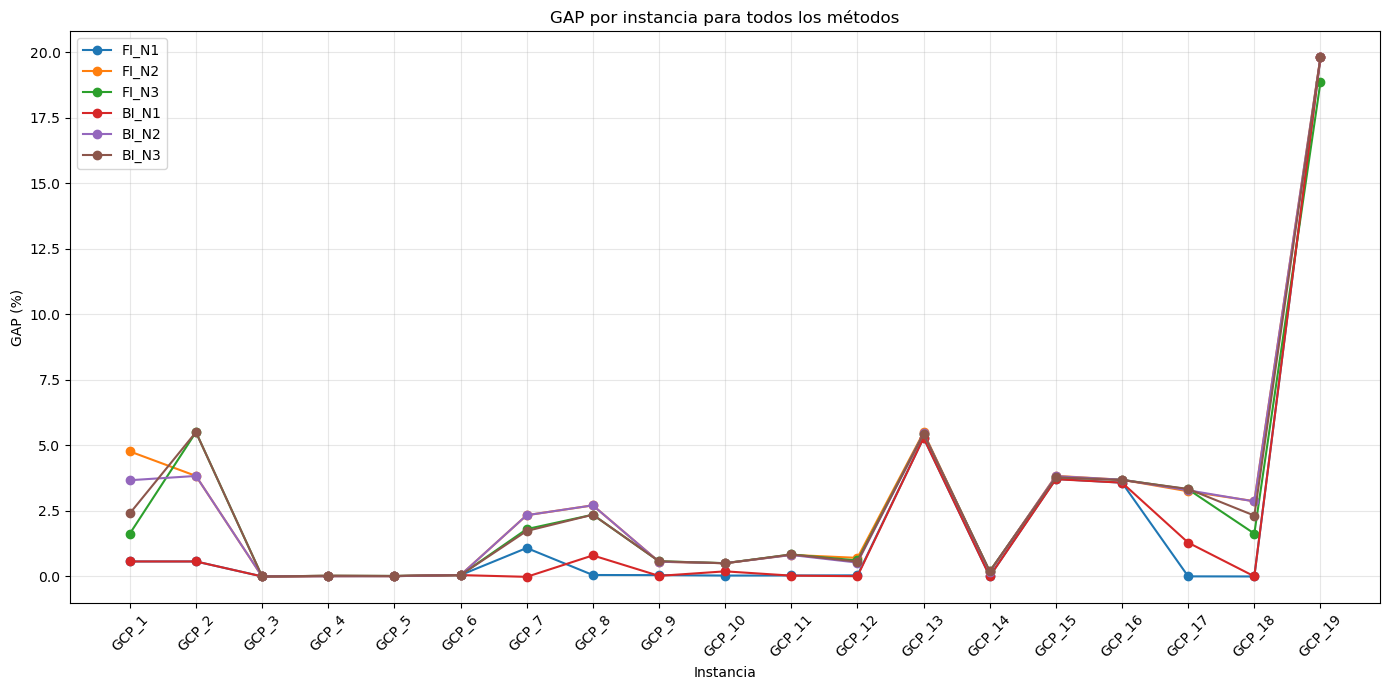

In [16]:
plt.figure(figsize=(14, 7))

for metodo in tabla_gap.columns:

    plt.plot(
        instancias,
        tabla_gap.loc[instancias, metodo],
        marker="o",
        label=metodo
    )

plt.xlabel("Instancia")
plt.ylabel("GAP (%)")
plt.title("GAP por instancia para todos los métodos")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Tiempo de computo

In [17]:
tabla_tiempo = pd.DataFrame(
    index=instancias,
    columns=list(datos.keys()),
    dtype=float
)

for metodo in datos:

    for instancia in instancias:

        if instancia in datos[metodo]:

            tabla_tiempo.loc[
                instancia,
                metodo
            ] = datos[metodo][instancia]["tiempo"]

tabla_tiempo.loc["PROMEDIO"] = tabla_tiempo.mean()

print("TIEMPO DE CÓMPUTO (s)")

display(tabla_tiempo.round(4))

TIEMPO DE CÓMPUTO (s)


,FI_N1,FI_N2,FI_N3,BI_N1,BI_N2,BI_N3
GCP_1,0.0000,0.0000,0.0000,0.0000,0.00,0.0000
GCP_2,0.0000,0.0000,0.0000,0.0000,0.00,0.0000
GCP_3,0.0000,0.0000,0.0000,0.0000,0.00,0.0000
GCP_4,0.1000,0.0300,0.1300,0.9600,0.08,0.2100
GCP_5,0.1300,0.0300,0.1300,0.4300,0.07,0.2600
GCP_6,0.0000,0.0100,0.0000,0.0000,0.01,0.0000
GCP_7,0.0600,0.0200,0.0100,0.5100,0.05,0.0300
GCP_8,0.1400,0.0100,0.0000,0.5100,0.01,0.0100
GCP_9,0.4000,0.0400,0.0300,14.9300,0.18,0.0300
GCP_10,0.2800,0.0400,0.0300,4.5800,0.15,0.0500


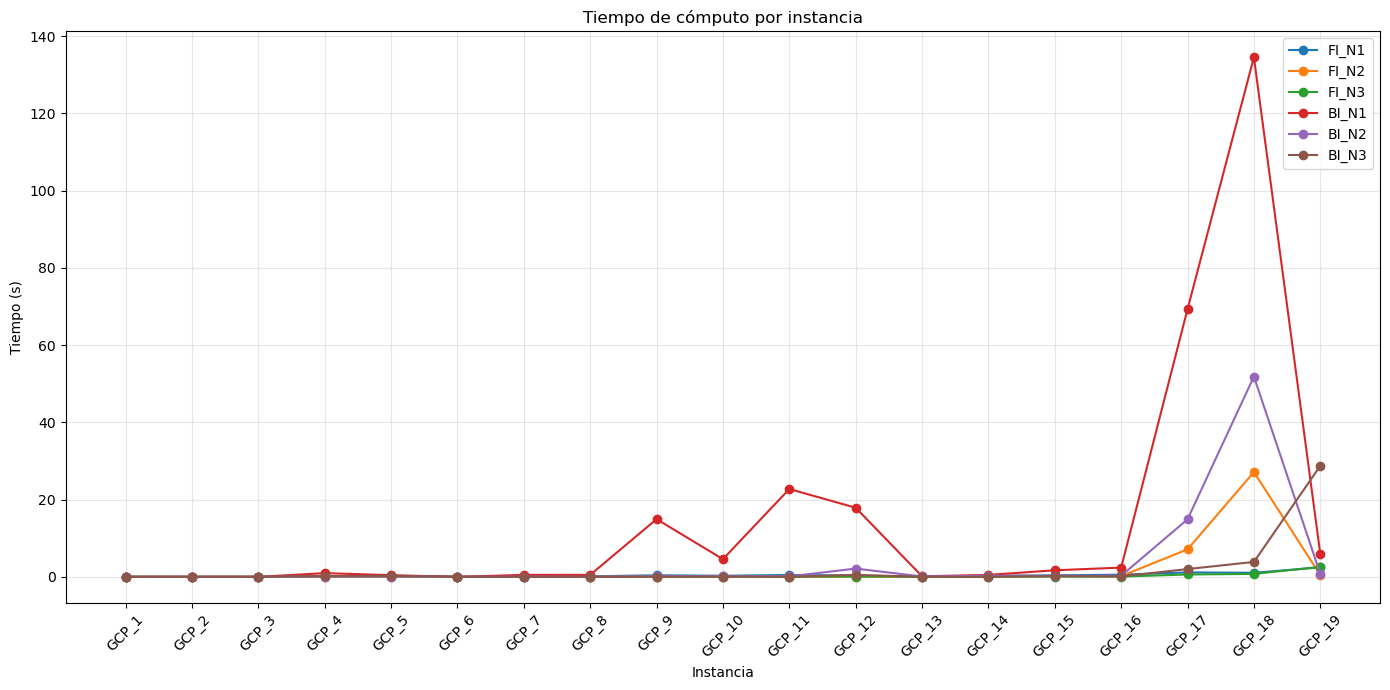

In [18]:
plt.figure(figsize=(14, 7))

for metodo in tabla_tiempo.columns:

    plt.plot(
        instancias,
        tabla_tiempo.loc[instancias, metodo],
        marker="o",
        label=metodo
    )

plt.xlabel("Instancia")
plt.ylabel("Tiempo (s)")
plt.title("Tiempo de cómputo por instancia")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Promedios

In [19]:
resumen = pd.DataFrame(index=list(datos.keys()))

resumen["GAP promedio (%)"] = [
    tabla_gap.loc["PROMEDIO", metodo]
    for metodo in datos.keys()
]

resumen["Tiempo promedio (s)"] = [
    tabla_tiempo.loc["PROMEDIO", metodo]
    for metodo in datos.keys()
]

display(resumen.round(4))

,GAP promedio (%),Tiempo promedio (s)
FI_N1,1.8388,0.4116
FI_N2,2.9207,1.8747
FI_N3,2.6784,0.2374
BI_N1,1.8922,14.5816
BI_N2,2.8518,3.7500
BI_N3,2.7981,1.8968


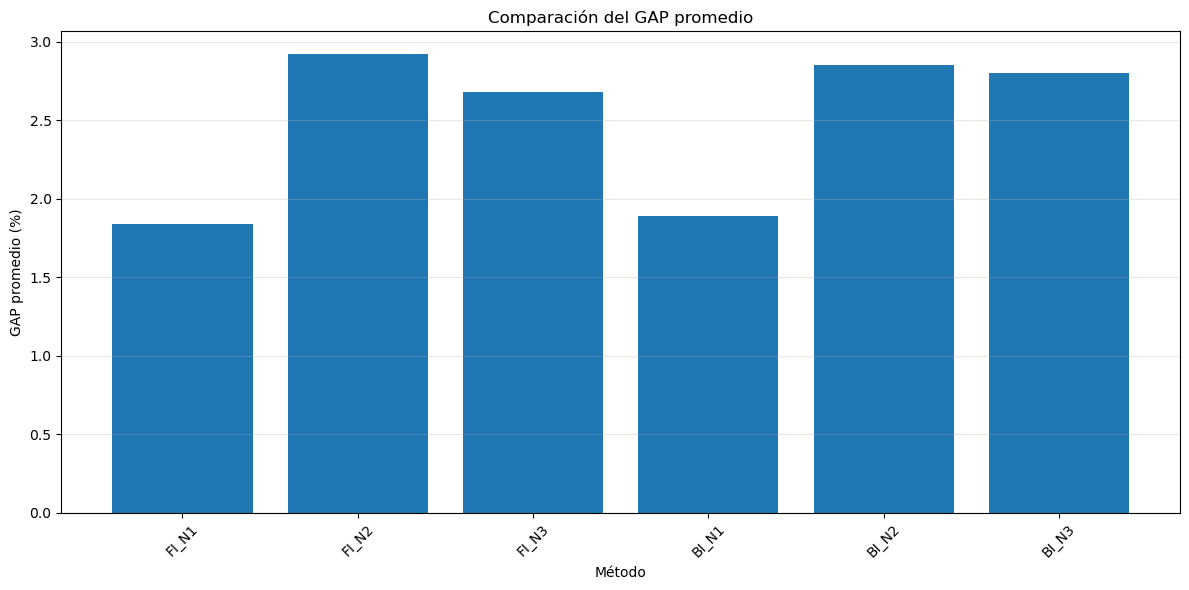

In [20]:
plt.figure(figsize=(12, 6))

plt.bar(
    resumen.index,
    resumen["GAP promedio (%)"]
)

plt.xlabel("Método")
plt.ylabel("GAP promedio (%)")
plt.title("Comparación del GAP promedio")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

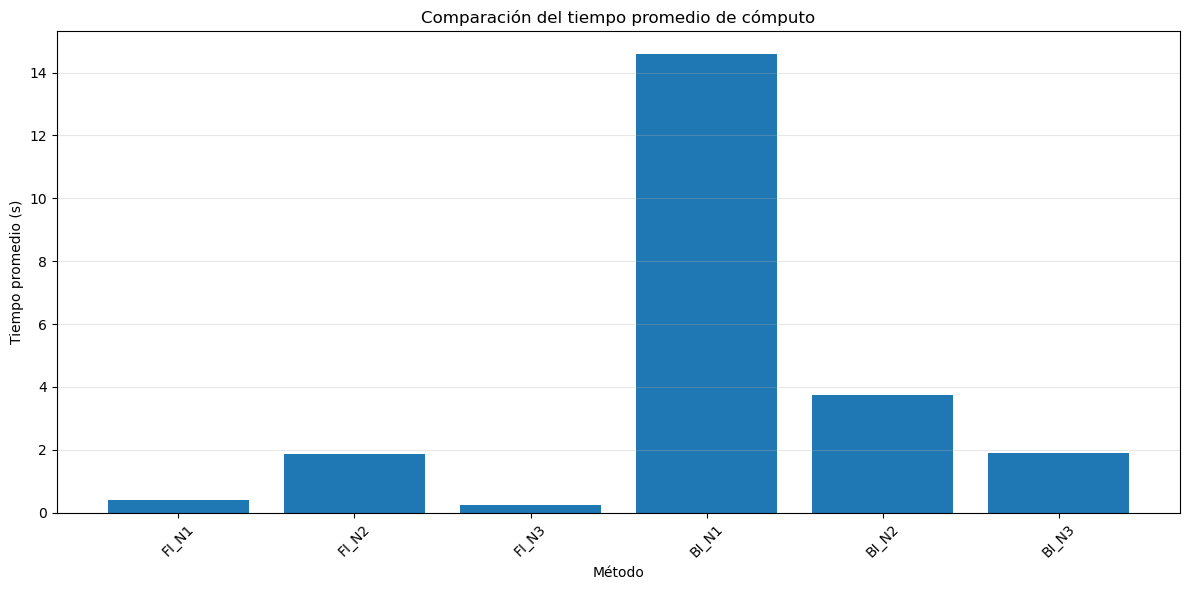

In [21]:
plt.figure(figsize=(12, 6))

plt.bar(
    resumen.index,
    resumen["Tiempo promedio (s)"]
)

plt.xlabel("Método")
plt.ylabel("Tiempo promedio (s)")
plt.title("Comparación del tiempo promedio de cómputo")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Comparaciones métodos constructivos y aleatorizados

#### GAP

In [22]:
nombre_base = "GCP_JeronimoGil"

metodos = [
    "constructivo",
    "GRASP",
    "Ruido",
    "FI_N1",
    "FI_N2",
    "FI_N3",
    "BI_N1",
    "BI_N2",
    "BI_N3"
]

carpeta_entrega1 = Path("soluciones_entrega1")

archivos = {
    "Constructivo": carpeta_entrega1 / f"{nombre_base}_constructivo.xlsx",
    "GRASP": carpeta_entrega1 / f"{nombre_base}_GRASP.xlsx",
    "Ruido": carpeta_entrega1 / f"{nombre_base}_Ruido.xlsx",

    "FI_N1": Path(f"{nombre_base}_FI_N1.xlsx"),
    "FI_N2": Path(f"{nombre_base}_FI_N2.xlsx"),
    "FI_N3": Path(f"{nombre_base}_FI_N3.xlsx"),
    "BI_N1": Path(f"{nombre_base}_BI_N1.xlsx"),
    "BI_N2": Path(f"{nombre_base}_BI_N2.xlsx"),
    "BI_N3": Path(f"{nombre_base}_BI_N3.xlsx")
}

bks = {}
with open("BKS1.txt", "r", encoding="utf-8") as archivo:
    for i, linea in enumerate(archivo, start=1):
        linea = linea.strip()

        if linea:
            bks[f"GCP_{i}"] = float(linea.replace(",", "."))

datos = {}
for metodo, nombre_archivo in archivos.items():
    ruta = Path(nombre_archivo)
    if not ruta.exists():
        print(f"\nADVERTENCIA: no se encontró {nombre_archivo}")
        continue
    wb = openpyxl.load_workbook(
        nombre_archivo,
        data_only=True
    )
    datos[metodo] = {}
    for ws in wb.worksheets:

        instancia = ws.title
        fila = list(
            ws.iter_rows(
                min_row=2,
                max_row=2,
                values_only=True
            )
        )[0]

        z1 = fila[0]
        z2 = fila[1]
        fo = float(fila[2])
        tiempo = float(fila[3])
        bks_valor = bks[instancia]
        gap = 100 * (fo - bks_valor) / bks_valor
        datos[metodo][instancia] = {
            "z1": z1,
            "z2": z2,
            "fo": fo,
            "tiempo": tiempo,
            "bks": bks_valor,
            "gap": gap
        }

print("\nArchivos cargados correctamente.")

instancias = [f"GCP_{i}" for i in range(1, 20)]

tabla_gap = pd.DataFrame(
    index=instancias,
    columns=list(datos.keys()),
    dtype=float
)

for metodo in datos:

    for instancia in instancias:

        if instancia in datos[metodo]:

            tabla_gap.loc[
                instancia,
                metodo
            ] = datos[metodo][instancia]["gap"]

tabla_gap.loc["PROMEDIO"] = tabla_gap.mean()
print("GAP (%)")

display(tabla_gap.round(2))


Archivos cargados correctamente.
GAP (%)


,Constructivo,GRASP,Ruido,FI_N1,FI_N2,FI_N3,BI_N1,BI_N2,BI_N3
GCP_1,5.63,3.55,6.65,0.57,4.77,1.63,0.57,3.67,2.41
GCP_2,6.24,4.12,5.51,0.57,3.84,5.51,0.57,3.84,5.51
GCP_3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
GCP_4,0.01,0.02,0.03,0.01,0.02,0.02,0.01,0.02,0.02
GCP_5,0.03,0.02,0.03,0.01,0.01,0.02,0.01,0.01,0.02
GCP_6,10.70,0.03,0.05,0.05,0.05,0.05,0.05,0.05,0.05
GCP_7,0.72,2.49,2.44,1.09,2.34,1.81,-0.01,2.34,1.74
GCP_8,0.47,2.61,2.71,0.05,2.71,2.36,0.80,2.71,2.36
GCP_9,0.10,0.57,0.58,0.05,0.56,0.58,0.02,0.56,0.58
GCP_10,0.00,0.52,0.52,0.03,0.51,0.51,0.19,0.51,0.50


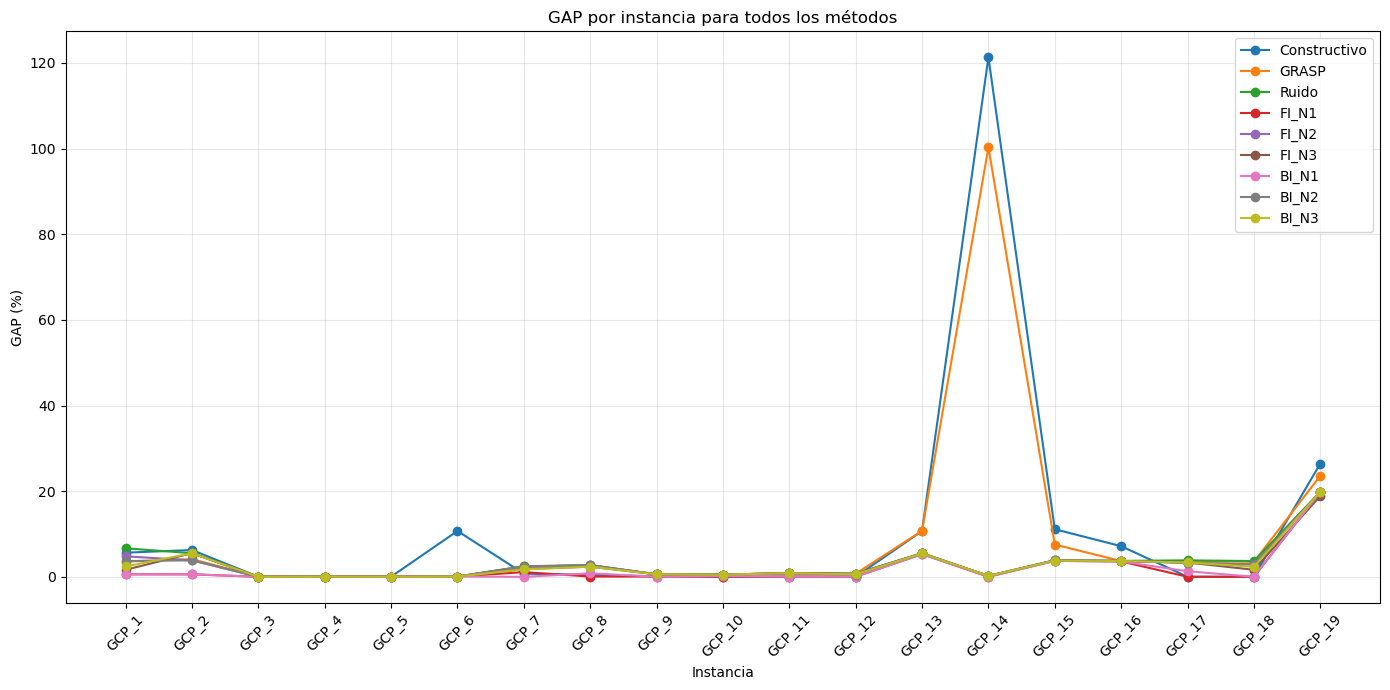

In [23]:
plt.figure(figsize=(14, 7))

for metodo in tabla_gap.columns:

    plt.plot(
        instancias,
        tabla_gap.loc[instancias, metodo],
        marker="o",
        label=metodo
    )

plt.xlabel("Instancia")
plt.ylabel("GAP (%)")
plt.title("GAP por instancia para todos los métodos")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Tiempo de computo

In [24]:
tabla_tiempo = pd.DataFrame(
    index=instancias,
    columns=list(datos.keys()),
    dtype=float
)

for metodo in datos:

    for instancia in instancias:

        if instancia in datos[metodo]:

            tabla_tiempo.loc[
                instancia,
                metodo
            ] = datos[metodo][instancia]["tiempo"]

tabla_tiempo.loc["PROMEDIO"] = tabla_tiempo.mean()

print("TIEMPO DE CÓMPUTO (s)")

display(tabla_tiempo.round(4))

TIEMPO DE CÓMPUTO (s)


,Constructivo,GRASP,Ruido,FI_N1,FI_N2,FI_N3,BI_N1,BI_N2,BI_N3
GCP_1,0.0000,0.01,0.0000,0.0000,0.0000,0.0000,0.0000,0.00,0.0000
GCP_2,0.0000,0.01,0.0000,0.0000,0.0000,0.0000,0.0000,0.00,0.0000
GCP_3,0.0100,0.10,0.0000,0.0000,0.0000,0.0000,0.0000,0.00,0.0000
GCP_4,0.1100,0.83,0.0000,0.1000,0.0300,0.1300,0.9600,0.08,0.2100
GCP_5,0.1100,0.53,0.0000,0.1300,0.0300,0.1300,0.4300,0.07,0.2600
GCP_6,0.0800,1.04,0.0000,0.0000,0.0100,0.0000,0.0000,0.01,0.0000
GCP_7,0.0500,1.12,0.0000,0.0600,0.0200,0.0100,0.5100,0.05,0.0300
GCP_8,0.0400,0.95,0.0000,0.1400,0.0100,0.0000,0.5100,0.01,0.0100
GCP_9,0.1600,1.23,0.0000,0.4000,0.0400,0.0300,14.9300,0.18,0.0300
GCP_10,0.1600,1.03,0.0000,0.2800,0.0400,0.0300,4.5800,0.15,0.0500


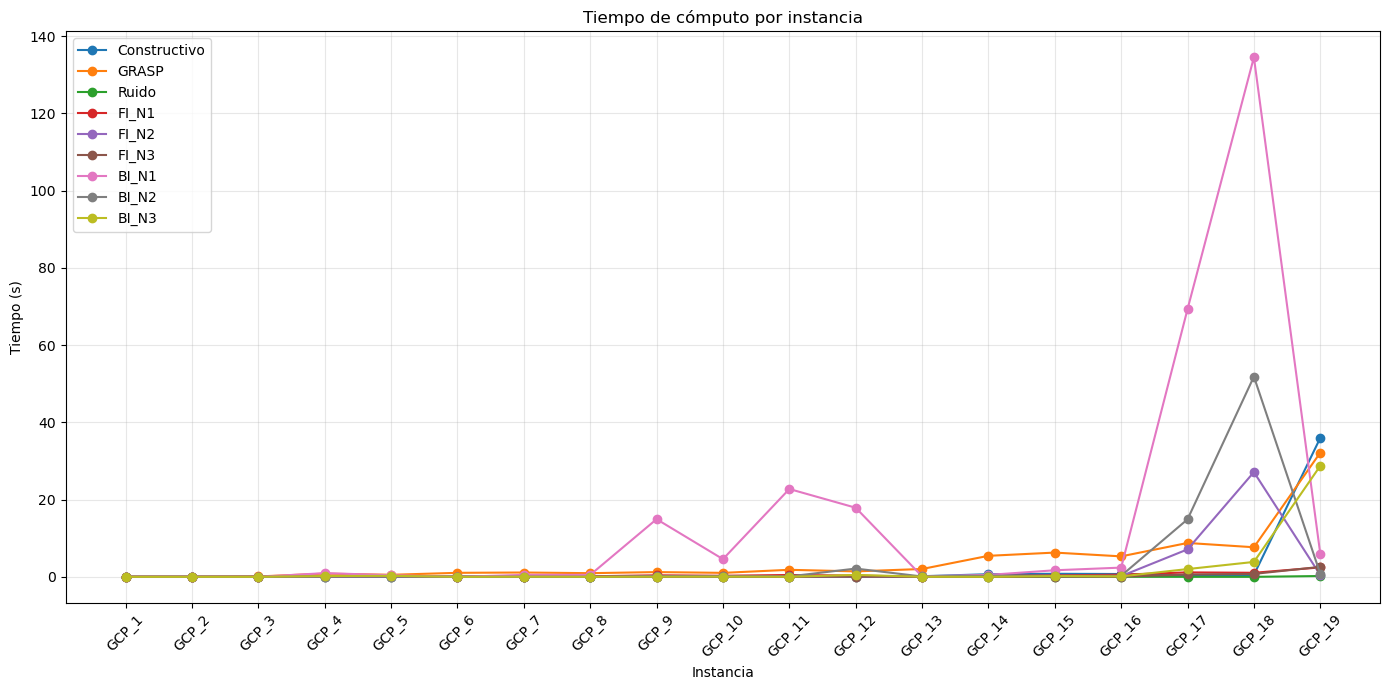

In [25]:
plt.figure(figsize=(14, 7))

for metodo in tabla_tiempo.columns:

    plt.plot(
        instancias,
        tabla_tiempo.loc[instancias, metodo],
        marker="o",
        label=metodo
    )

plt.xlabel("Instancia")
plt.ylabel("Tiempo (s)")
plt.title("Tiempo de cómputo por instancia")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:
resumen = pd.DataFrame(index=list(datos.keys()))

resumen["GAP promedio (%)"] = [
    tabla_gap.loc["PROMEDIO", metodo]
    for metodo in datos.keys()
]

resumen["Tiempo promedio (s)"] = [
    tabla_tiempo.loc["PROMEDIO", metodo]
    for metodo in datos.keys()
]

display(resumen.round(4))

,GAP promedio (%),Tiempo promedio (s)
Constructivo,10.5581,2.1189
GRASP,8.8651,4.0900
Ruido,3.1940,0.0132
FI_N1,1.8388,0.4116
FI_N2,2.9207,1.8747
FI_N3,2.6784,0.2374
BI_N1,1.8922,14.5816
BI_N2,2.8518,3.7500
BI_N3,2.7981,1.8968


#### Promedios

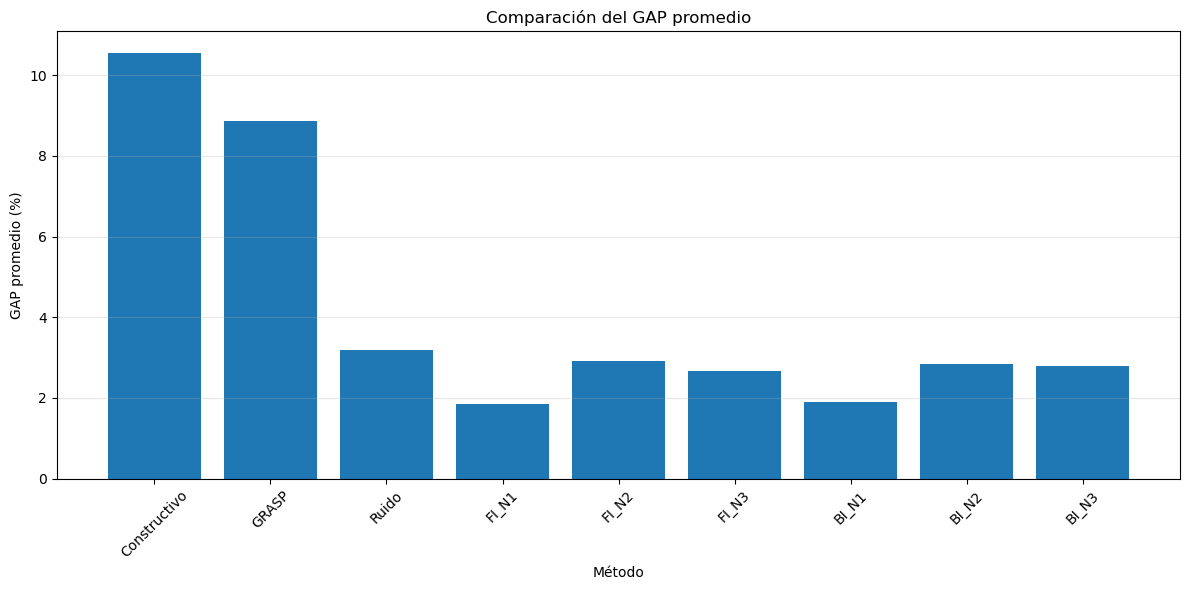

In [27]:
plt.figure(figsize=(12, 6))

plt.bar(
    resumen.index,
    resumen["GAP promedio (%)"]
)

plt.xlabel("Método")
plt.ylabel("GAP promedio (%)")
plt.title("Comparación del GAP promedio")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

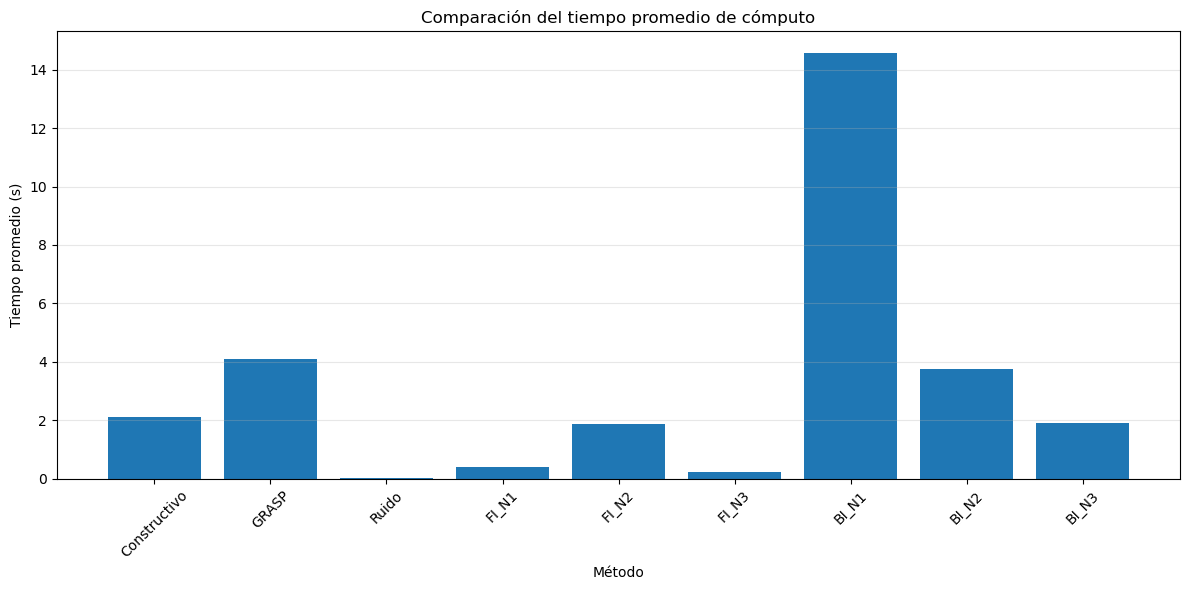

In [28]:
plt.figure(figsize=(12, 6))

plt.bar(
    resumen.index,
    resumen["Tiempo promedio (s)"]
)

plt.xlabel("Método")
plt.ylabel("Tiempo promedio (s)")
plt.title("Comparación del tiempo promedio de cómputo")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()